<a id='1'></a><center> <h3 style="background-color:orange; color:white" ><br>Superstore Sales Analytics Assignment<br></h3></center>

# Introduction
This Jupyter notebook is part of your learning experience in Data Analytics using Python. In this assignment, we analyze the classic **Superstore retail dataset** — a rich transactional dataset covering orders, products, customers, regions, and returns across the United States from 2015–2018.

**Key objectives:**
- Perform end-to-end Exploratory Data Analysis (EDA) on a real-world retail dataset
- Analyze sales, profit, and discount patterns across categories, regions, and customer segments
- Merge multiple data tables (Orders, People, Returns) to derive richer insights
- Build visualizations to surface actionable business intelligence
- Apply aggregation, grouping, and time-series analysis techniques


In [1]:
# Task 1: Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
sns.set_theme(style='whitegrid', palette='Set2')

print("Libraries imported successfully!")


Libraries imported successfully!


---
## Task 2: Load the Dataset

Load all three sheets: **Orders**, **People**, and **Returns**.


In [2]:
# Task 2: Load Dataset
orders = pd.read_csv('Orders.csv', parse_dates=['Order Date', 'Ship Date'])
people = pd.read_csv('People.csv')
returns = pd.read_csv('Returns.csv')

print(f"Orders: {orders.shape[0]} rows × {orders.shape[1]} columns")
print(f"People: {people.shape}")
print(f"Returns: {returns.shape}")
orders.head()


Orders: 9994 rows × 21 columns
People: (4, 2)
Returns: (296, 2)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2018-152156,2018-11-08,2018-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2018-152156,2018-11-08,2018-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2018-138688,2018-06-12,2018-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2017-108966,2017-10-11,2017-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2017-108966,2017-10-11,2017-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


---
## Task 3: Data Overview & Quality Check


In [3]:
# Task 3a: Data Types & Info
print("=== Orders Info ===")
orders.info()


=== Orders Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          9994 non-null   int64         
 1   Order ID        9994 non-null   object        
 2   Order Date      9994 non-null   datetime64[ns]
 3   Ship Date       9994 non-null   datetime64[ns]
 4   Ship Mode       9994 non-null   object        
 5   Customer ID     9994 non-null   object        
 6   Customer Name   9994 non-null   object        
 7   Segment         9994 non-null   object        
 8   Country/Region  9994 non-null   object        
 9   City            9994 non-null   object        
 10  State           9994 non-null   object        
 11  Postal Code     9983 non-null   float64       
 12  Region          9994 non-null   object        
 13  Product ID      9994 non-null   object        
 14  Category        9994 non-null   obje

In [4]:
# Task 3b: Missing Values
print("Missing values per column:")
print(orders.isnull().sum())
print(f"\nTotal missing: {orders.isnull().sum().sum()}")


Missing values per column:
Row ID             0
Order ID           0
Order Date         0
Ship Date          0
Ship Mode          0
Customer ID        0
Customer Name      0
Segment            0
Country/Region     0
City               0
State              0
Postal Code       11
Region             0
Product ID         0
Category           0
Sub-Category       0
Product Name       0
Sales              0
Quantity           0
Discount           0
Profit             0
dtype: int64

Total missing: 11


In [5]:
# Task 3c: Basic Statistics
orders[['Sales', 'Quantity', 'Discount', 'Profit']].describe().round(2)


,Sales,Quantity,Discount,Profit
count,9994.00,9994.00,9994.00,9994.00
mean,229.86,3.79,0.16,28.66
std,623.25,2.23,0.21,234.26
min,0.44,1.00,0.00,-6599.98
25%,17.28,2.00,0.00,1.73
50%,54.49,3.00,0.20,8.67
75%,209.94,5.00,0.20,29.36
max,22638.48,14.00,0.80,8399.98


In [6]:
# Task 3d: Duplicate Check
dupes = orders.duplicated().sum()
print(f"Duplicate rows: {dupes}")
print(f"\nUnique Orders: {orders['Order ID'].nunique()}")
print(f"Unique Customers: {orders['Customer Name'].nunique()}")
print(f"Unique Products: {orders['Product Name'].nunique()}")
print(f"Date Range: {orders['Order Date'].min().date()} → {orders['Order Date'].max().date()}")


Duplicate rows: 0

Unique Orders: 5009
Unique Customers: 793
Unique Products: 1850
Date Range: 2016-01-03 → 2019-12-30


---
## Task 4: Feature Engineering

Create derived columns for deeper analysis.


In [7]:
# Task 4: Feature Engineering
# Extract year, month, quarter from Order Date
orders['Year'] = orders['Order Date'].dt.year
orders['Month'] = orders['Order Date'].dt.month
orders['Month Name'] = orders['Order Date'].dt.strftime('%b')
orders['Quarter'] = orders['Order Date'].dt.to_period('Q').astype(str)

# Profit Margin %
orders['Profit Margin %'] = (orders['Profit'] / orders['Sales'] * 100).round(2)

# Shipping Duration (days)
orders['Ship Days'] = (orders['Ship Date'] - orders['Order Date']).dt.days

# Loss flag
orders['Is_Loss'] = orders['Profit'] < 0

print("Feature engineering complete!")
orders[['Order Date','Year','Month Name','Quarter','Profit Margin %','Ship Days','Is_Loss']].head()


Feature engineering complete!


,Order Date,Year,Month Name,Quarter,Profit Margin %,Ship Days,Is_Loss
0,2018-11-08,2018,Nov,2018Q4,16.00,3,False
1,2018-11-08,2018,Nov,2018Q4,30.00,3,False
2,2018-06-12,2018,Jun,2018Q2,47.00,4,False
3,2017-10-11,2017,Oct,2017Q4,-40.00,7,True
4,2017-10-11,2017,Oct,2017Q4,11.25,7,False


---
## Task 5: Sales & Profit by Category


                 Total_Sales  Total_Profit  Orders  Avg_Discount  \
Category                                                           
Technology         836154.03     145454.95    1847          0.13   
Furniture          741999.80      18451.27    2121          0.17   
Office Supplies    719047.03     122490.80    6026          0.16   

                 Profit_Margin%  
Category                         
Technology                17.40  
Furniture                  2.49  
Office Supplies           17.04  


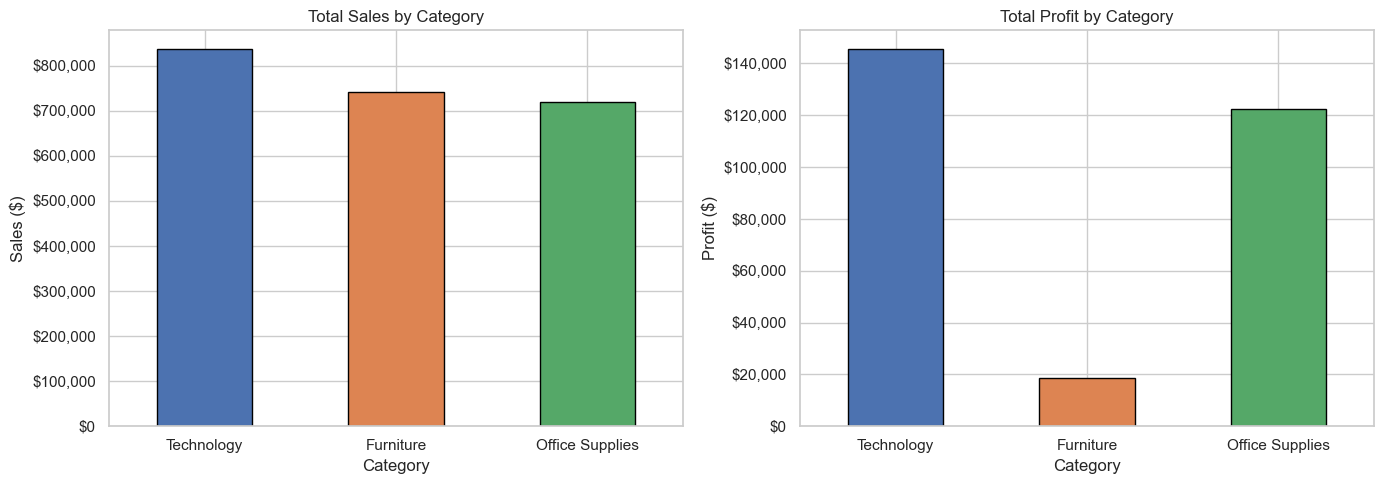

In [8]:
# Task 5: Sales & Profit by Category
cat_summary = orders.groupby('Category').agg(
    Total_Sales=('Sales','sum'),
    Total_Profit=('Profit','sum'),
    Orders=('Order ID','count'),
    Avg_Discount=('Discount','mean')
).round(2).sort_values('Total_Sales', ascending=False)

cat_summary['Profit_Margin%'] = (cat_summary['Total_Profit'] / cat_summary['Total_Sales'] * 100).round(2)
print(cat_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cat_summary['Total_Sales'].plot(kind='bar', ax=axes[0], color=['#4C72B0','#DD8452','#55A868'], edgecolor='black')
axes[0].set_title('Total Sales by Category')
axes[0].set_xlabel('Category')
axes[0].set_ylabel('Sales ($)')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'\${x:,.0f}'))
axes[0].tick_params(axis='x', rotation=0)

cat_summary['Total_Profit'].plot(kind='bar', ax=axes[1], color=['#4C72B0','#DD8452','#55A868'], edgecolor='black')
axes[1].set_title('Total Profit by Category')
axes[1].set_xlabel('Category')
axes[1].set_ylabel('Profit ($)')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'\${x:,.0f}'))
axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()


---
## Task 6: Sub-Category Analysis


In [9]:
# Task 6: Sub-Category Performance
sub_perf = orders.groupby(['Category','Sub-Category']).agg(
    Sales=('Sales','sum'),
    Profit=('Profit','sum')
).round(2).reset_index().sort_values('Profit', ascending=False)

sub_perf['Profit_Margin%'] = (sub_perf['Profit'] / sub_perf['Sales'] * 100).round(2)
print(sub_perf.to_string(index=False))


       Category Sub-Category     Sales    Profit  Profit_Margin%
     Technology      Copiers 149528.03  55617.82           37.20
     Technology       Phones 330007.05  44515.73           13.49
     Technology  Accessories 167380.32  41936.64           25.05
Office Supplies        Paper  78479.21  34053.57           43.39
Office Supplies      Binders 203412.73  30221.76           14.86
      Furniture       Chairs 328449.10  26590.17            8.10
Office Supplies      Storage 223843.61  21278.83            9.51
Office Supplies   Appliances 107532.16  18138.01           16.87
      Furniture  Furnishings  91705.16  13059.14           14.24
Office Supplies    Envelopes  16476.40   6964.18           42.27
Office Supplies          Art  27118.79   6527.79           24.07
Office Supplies       Labels  12486.31   5546.25           44.42
     Technology     Machines 189238.63   3384.76            1.79
Office Supplies    Fasteners   3024.28    949.52           31.40
Office Supplies     Suppl

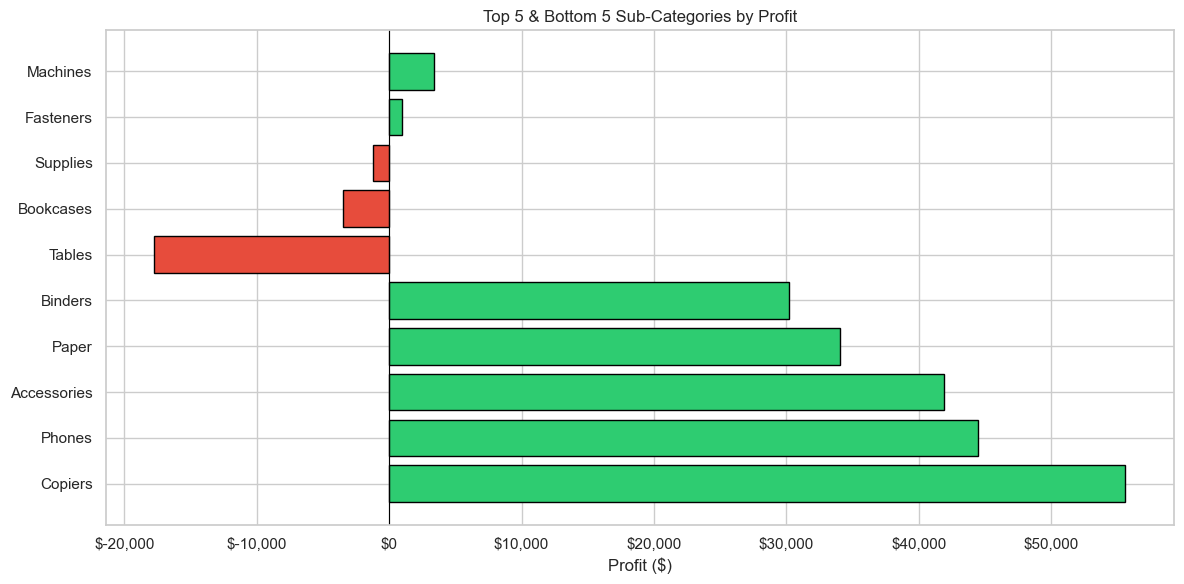

In [10]:
# Task 6b: Top & Bottom Sub-Categories by Profit
top5 = sub_perf.nlargest(5, 'Profit')
bot5 = sub_perf.nsmallest(5, 'Profit')
combined = pd.concat([top5, bot5])

colors = ['#2ecc71' if p >= 0 else '#e74c3c' for p in combined['Profit']]
fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(combined['Sub-Category'], combined['Profit'], color=colors, edgecolor='black')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Top 5 & Bottom 5 Sub-Categories by Profit')
ax.set_xlabel('Profit ($)')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'\${x:,.0f}'))
plt.tight_layout()
plt.show()


---
## Task 7: Regional Analysis


             Sales     Profit  Orders  Customers  Profit_Margin%
Region                                                          
West     725457.82  108418.45    3203        686           14.94
East     678781.24   91522.78    2848        674           13.48
Central  501239.89   39706.36    2323        629            7.92
South    391721.90   46749.43    1620        512           11.93


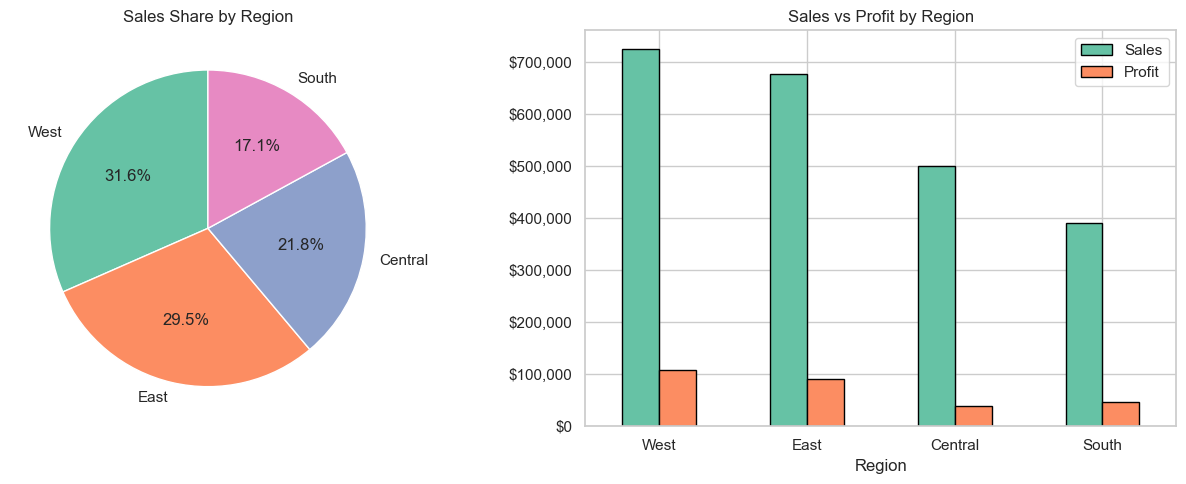

In [11]:
# Task 7: Sales & Profit by Region
region_summary = orders.groupby('Region').agg(
    Sales=('Sales','sum'),
    Profit=('Profit','sum'),
    Orders=('Order ID','count'),
    Customers=('Customer Name','nunique')
).round(2).sort_values('Sales', ascending=False)
region_summary['Profit_Margin%'] = (region_summary['Profit']/region_summary['Sales']*100).round(2)
print(region_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].pie(region_summary['Sales'], labels=region_summary.index, autopct='%1.1f%%',
            colors=sns.color_palette('Set2', 4), startangle=90)
axes[0].set_title('Sales Share by Region')

region_summary[['Sales','Profit']].plot(kind='bar', ax=axes[1], edgecolor='black')
axes[1].set_title('Sales vs Profit by Region')
axes[1].set_xlabel('Region')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'\${x:,.0f}'))
axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()


---
## Task 8: Customer Segment Analysis


                  Sales     Profit  Orders  Customers  Profit_Margin%  \
Segment                                                                 
Consumer     1161401.34  134119.21    5191        409           11.55   
Corporate     706146.37   91979.13    3020        236           13.03   
Home Office   429653.15   60298.68    1783        148           14.03   

             Avg_Order_Value  
Segment                       
Consumer              223.73  
Corporate             233.82  
Home Office           240.97  


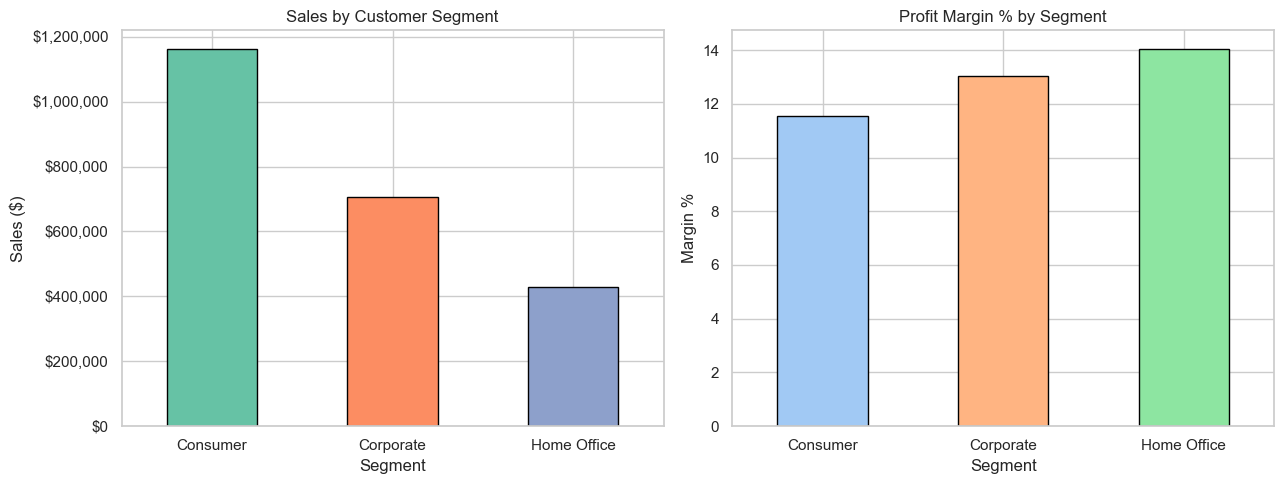

In [12]:
# Task 8: Segment Breakdown
seg = orders.groupby('Segment').agg(
    Sales=('Sales','sum'),
    Profit=('Profit','sum'),
    Orders=('Order ID','count'),
    Customers=('Customer Name','nunique')
).round(2)
seg['Profit_Margin%'] = (seg['Profit']/seg['Sales']*100).round(2)
seg['Avg_Order_Value'] = (seg['Sales']/seg['Orders']).round(2)
print(seg)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
seg['Sales'].plot(kind='bar', ax=axes[0], color=sns.color_palette('Set2',3), edgecolor='black')
axes[0].set_title('Sales by Customer Segment')
axes[0].set_ylabel('Sales ($)')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'\${x:,.0f}'))
axes[0].tick_params(axis='x', rotation=0)

seg['Profit_Margin%'].plot(kind='bar', ax=axes[1], color=sns.color_palette('pastel',3), edgecolor='black')
axes[1].set_title('Profit Margin % by Segment')
axes[1].set_ylabel('Margin %')
axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()


---
## Task 9: Discount Impact on Profit


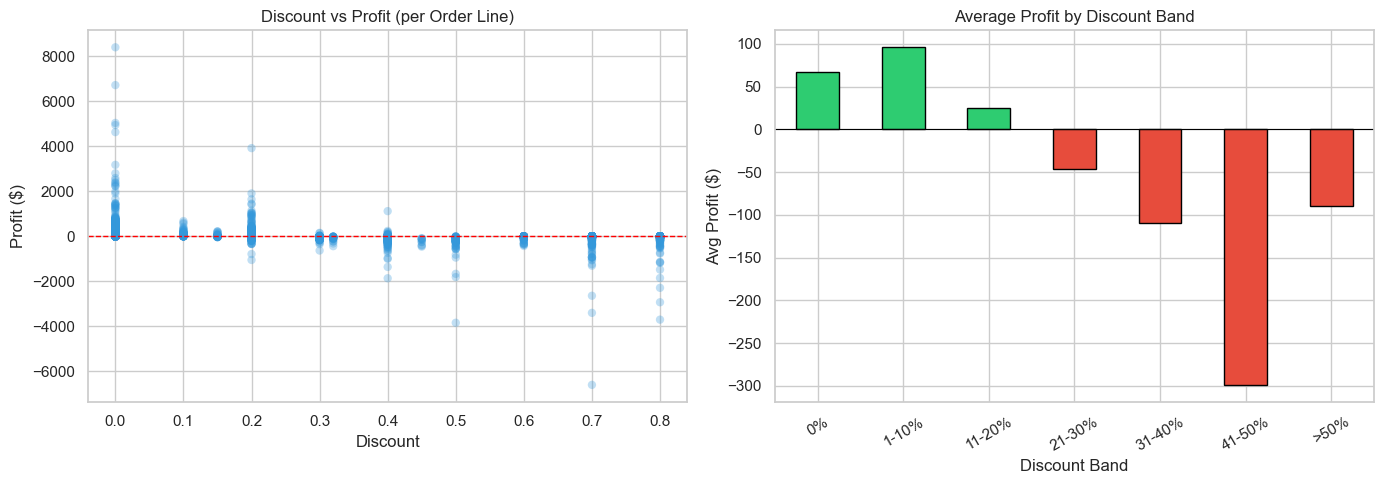

Correlation (Discount vs Profit): -0.2195


In [13]:
# Task 9: Discount vs Profit Analysis
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter: Discount vs Profit
axes[0].scatter(orders['Discount'], orders['Profit'], alpha=0.3, color='#3498db', edgecolors='none')
axes[0].axhline(0, color='red', linestyle='--', linewidth=1)
axes[0].set_title('Discount vs Profit (per Order Line)')
axes[0].set_xlabel('Discount')
axes[0].set_ylabel('Profit ($)')

# Avg profit by discount band
orders['Discount Band'] = pd.cut(orders['Discount'],
    bins=[-0.01, 0, 0.1, 0.2, 0.3, 0.4, 0.5, 1.0],
    labels=['0%','1-10%','11-20%','21-30%','31-40%','41-50%','>50%'])
disc_profit = orders.groupby('Discount Band', observed=True)['Profit'].mean().round(2)
disc_profit.plot(kind='bar', ax=axes[1], color=['#2ecc71' if v>0 else '#e74c3c' for v in disc_profit], edgecolor='black')
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_title('Average Profit by Discount Band')
axes[1].set_xlabel('Discount Band')
axes[1].set_ylabel('Avg Profit ($)')
axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

corr = orders['Discount'].corr(orders['Profit'])
print(f"Correlation (Discount vs Profit): {corr:.4f}")


---
## Task 10: Time Series — Sales & Profit Trends


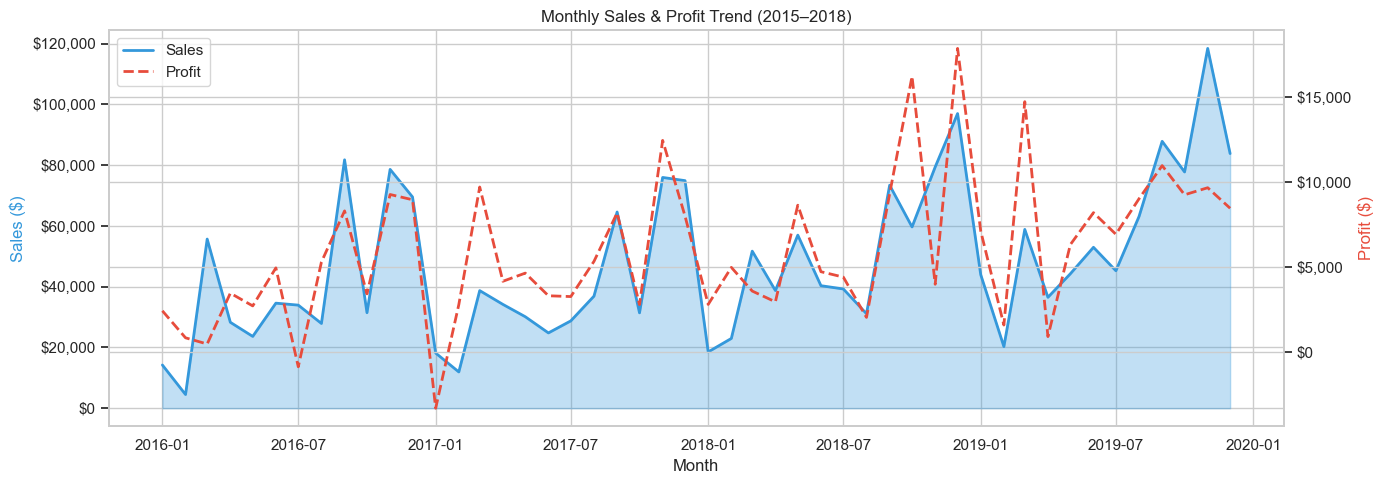

In [14]:
# Task 10: Monthly Sales & Profit Trends
monthly = orders.groupby(['Year','Month']).agg(Sales=('Sales','sum'), Profit=('Profit','sum')).round(2)
monthly = monthly.reset_index()
monthly['Period'] = pd.to_datetime(monthly[['Year','Month']].assign(Day=1))
monthly = monthly.sort_values('Period')

fig, ax1 = plt.subplots(figsize=(14, 5))
ax2 = ax1.twinx()
ax1.fill_between(monthly['Period'], monthly['Sales'], alpha=0.3, color='#3498db')
ax1.plot(monthly['Period'], monthly['Sales'], color='#3498db', linewidth=2, label='Sales')
ax2.plot(monthly['Period'], monthly['Profit'], color='#e74c3c', linewidth=2, linestyle='--', label='Profit')
ax1.set_title('Monthly Sales & Profit Trend (2015–2018)')
ax1.set_xlabel('Month')
ax1.set_ylabel('Sales ($)', color='#3498db')
ax2.set_ylabel('Profit ($)', color='#e74c3c')
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'\${x:,.0f}'))
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'\${x:,.0f}'))
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1+lines2, labels1+labels2, loc='upper left')
plt.tight_layout()
plt.show()


In [15]:
# Task 10b: Yearly Summary
yearly = orders.groupby('Year').agg(Sales=('Sales','sum'), Profit=('Profit','sum'), Orders=('Order ID','count')).round(2)
yearly['Growth_Sales%'] = yearly['Sales'].pct_change()*100
yearly['Profit_Margin%'] = (yearly['Profit']/yearly['Sales']*100).round(2)
print(yearly.to_string())


          Sales    Profit  Orders  Growth_Sales%  Profit_Margin%
Year                                                            
2016  484247.50  49543.97    1993            NaN           10.23
2017  470532.51  61618.60    2102      -2.832227           13.10
2018  609205.60  81795.17    2587      29.471522           13.43
2019  733215.26  93439.27    3312      20.355962           12.74


---
## Task 11: Returns Analysis


Return Rate:
Returned
No     92.0
Yes     8.0
Name: proportion, dtype: float64

Returns by Category:
       Category  Returns  Total  Return Rate%
      Furniture      171   2121          8.06
Office Supplies      473   6026          7.85
     Technology      156   1847          8.45


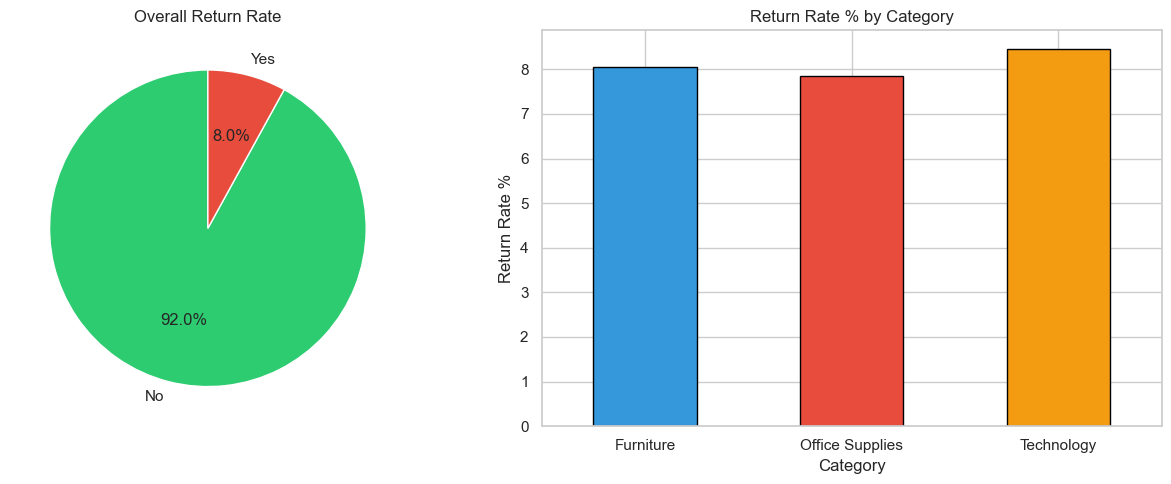

In [16]:
# Task 11: Merge Returns & Analyze
returns_clean = returns.copy()
returns_clean.columns = ['Returned','Order ID']
orders_with_returns = orders.merge(returns_clean, on='Order ID', how='left')
orders_with_returns['Returned'] = orders_with_returns['Returned'].fillna('No')

ret_rate = orders_with_returns['Returned'].value_counts(normalize=True)*100
print("Return Rate:")
print(ret_rate.round(2))

# Returns by Category
ret_cat = orders_with_returns[orders_with_returns['Returned']=='Yes'].groupby('Category').size().reset_index(name='Returns')
ret_total = orders_with_returns.groupby('Category').size().reset_index(name='Total')
ret_analysis = ret_cat.merge(ret_total, on='Category')
ret_analysis['Return Rate%'] = (ret_analysis['Returns']/ret_analysis['Total']*100).round(2)
print("\nReturns by Category:")
print(ret_analysis.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].pie(ret_rate, labels=ret_rate.index, autopct='%1.1f%%', colors=['#2ecc71','#e74c3c'], startangle=90)
axes[0].set_title('Overall Return Rate')

ret_analysis.set_index('Category')['Return Rate%'].plot(kind='bar', ax=axes[1], color=['#3498db','#e74c3c','#f39c12'], edgecolor='black')
axes[1].set_title('Return Rate % by Category')
axes[1].set_ylabel('Return Rate %')
axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()


---
## Task 12: Regional Manager Analysis (People Sheet)


                    Region      Sales     Profit  Orders  Profit_Margin%
Person                                                                  
Anna Andreadi         West  725457.82  108418.45    3203           14.94
Chuck Magee           East  678781.24   91522.78    2848           13.48
Kelly Williams     Central  501239.89   39706.36    2323            7.92
Cassandra Brandow    South  391721.90   46749.43    1620           11.93


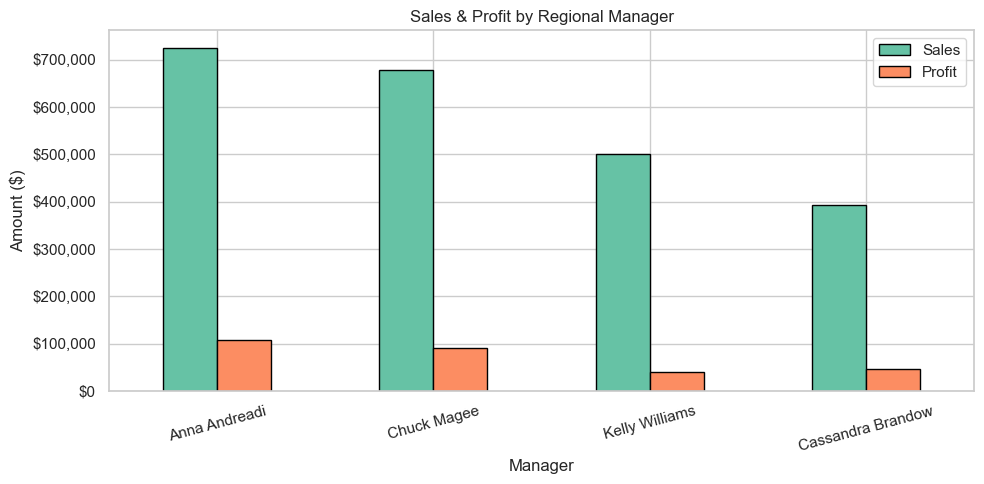

In [17]:
# Task 12: Merge People (Regional Managers) with Orders
orders_with_manager = orders.merge(people, on='Region', how='left')
manager_perf = orders_with_manager.groupby('Person').agg(
    Region=('Region','first'),
    Sales=('Sales','sum'),
    Profit=('Profit','sum'),
    Orders=('Order ID','count')
).round(2).sort_values('Sales', ascending=False)
manager_perf['Profit_Margin%'] = (manager_perf['Profit']/manager_perf['Sales']*100).round(2)
print(manager_perf.to_string())

manager_perf[['Sales','Profit']].plot(kind='bar', figsize=(10,5), edgecolor='black')
plt.title('Sales & Profit by Regional Manager')
plt.xlabel('Manager')
plt.ylabel('Amount ($)')
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'\${x:,.0f}'))
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


---
## Task 13: Top Customers & Products


=== Top 10 Customers by Sales ===
                       Sales   Profit  Orders
Customer Name                                
Sean Miller         25043.05 -1980.74       5
Tamara Chand        19052.22  8981.32       5
Raymond Buch        15117.34  6976.10       6
Tom Ashbrook        14595.62  4703.79       4
Adrian Barton       14473.57  5444.81      10
Ken Lonsdale        14175.23   806.85      12
Sanjit Chand        14142.33  5757.41       9
Hunter Lopez        12873.30  5622.43       6
Sanjit Engle        12209.44  2650.68      11
Christopher Conant  12129.07  2177.05       5


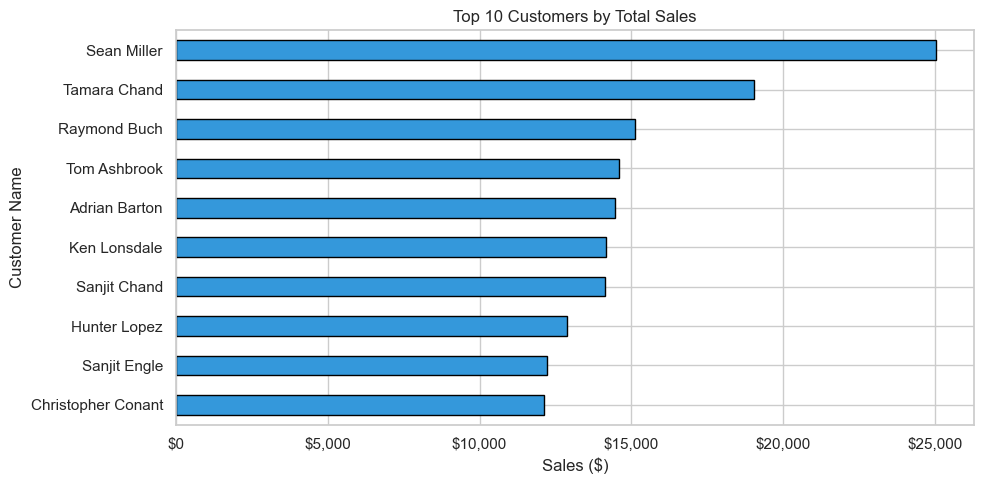

In [18]:
# Task 13a: Top 10 Customers by Sales
top_customers = orders.groupby('Customer Name').agg(
    Sales=('Sales','sum'), Profit=('Profit','sum'), Orders=('Order ID','nunique')
).round(2).nlargest(10, 'Sales')
print("=== Top 10 Customers by Sales ===")
print(top_customers.to_string())

top_customers['Sales'].sort_values().plot(kind='barh', figsize=(10,5), color='#3498db', edgecolor='black')
plt.title('Top 10 Customers by Total Sales')
plt.xlabel('Sales ($)')
plt.gca().xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'\${x:,.0f}'))
plt.tight_layout()
plt.show()


In [19]:
# Task 13b: Top 10 Products by Profit
top_products = orders.groupby('Product Name').agg(
    Sales=('Sales','sum'), Profit=('Profit','sum')
).round(2).nlargest(10, 'Profit')
print("=== Top 10 Products by Profit ===")
print(top_products.to_string())


=== Top 10 Products by Profit ===
                                                                                Sales    Profit
Product Name                                                                                   
Canon imageCLASS 2200 Advanced Copier                                        61599.82  25199.93
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind  27453.38   7753.04
Hewlett Packard LaserJet 3310 Copier                                         18839.69   6983.88
Canon PC1060 Personal Laser Copier                                           11619.83   4570.93
HP Designjet T520 Inkjet Large Format Printer - 24" Color                    18374.90   4094.98
Ativa V4110MDD Micro-Cut Shredder                                             7699.89   3772.95
3D Systems Cube Printer, 2nd Generation, Magenta                             14299.89   3717.97
Plantronics Savi W720 Multi-Device Wireless Headset System                    9367.29   3696.28
Ibico 

---
## Task 14: Heatmap — Sales by Region & Category


Category  Furniture  Office Supplies  Technology
Region                                          
Central   163797.16        167026.42   170416.31
East      208291.20        205516.06   264973.98
South     117298.68        125651.31   148771.91
West      252612.74        220853.25   251991.83


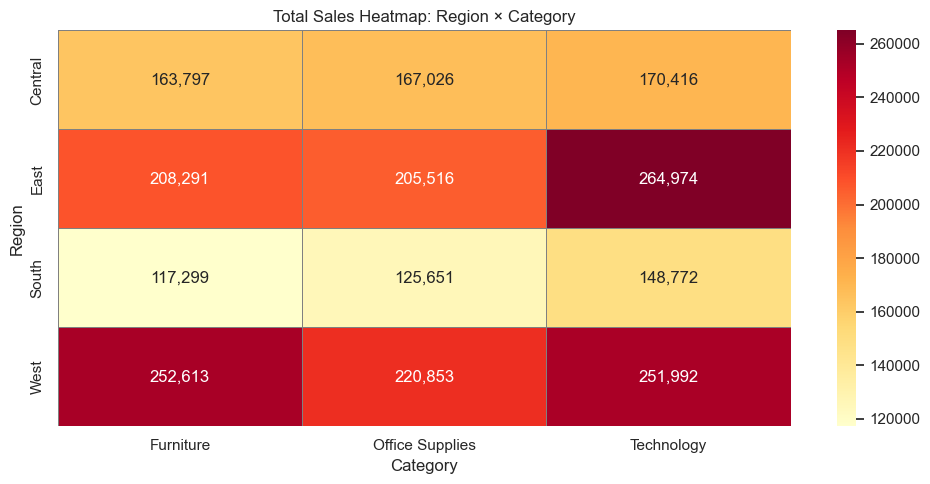

In [20]:
# Task 14: Pivot Heatmap
pivot = orders.pivot_table(values='Sales', index='Region', columns='Category', aggfunc='sum').round(2)
print(pivot)

plt.figure(figsize=(10, 5))
sns.heatmap(pivot, annot=True, fmt=',.0f', cmap='YlOrRd', linewidths=0.5, linecolor='grey')
plt.title('Total Sales Heatmap: Region × Category')
plt.tight_layout()
plt.show()


Category     Furniture  Office Supplies  Technology
Segment                                            
Consumer          3.04            12.88       15.27
Corporate         4.58            13.75       15.54
Home Office       5.21            16.57       16.69


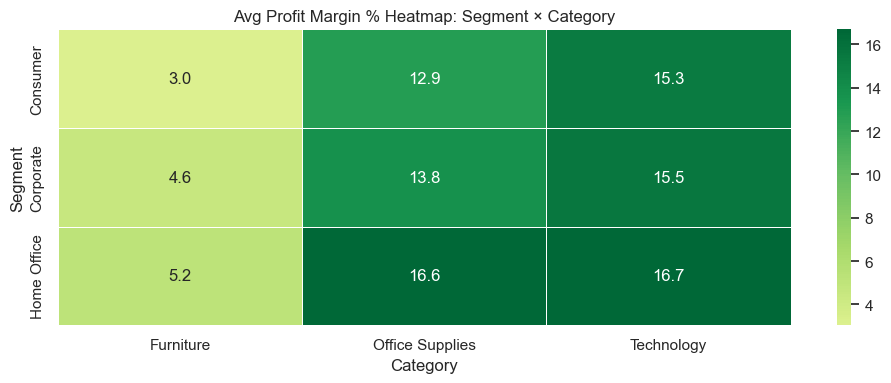

In [21]:
# Task 14b: Profit Margin Heatmap by Segment × Category
pivot2 = orders.pivot_table(values='Profit Margin %', index='Segment', columns='Category', aggfunc='mean').round(2)
print(pivot2)

plt.figure(figsize=(10, 4))
sns.heatmap(pivot2, annot=True, fmt='.1f', cmap='RdYlGn', center=0, linewidths=0.5)
plt.title('Avg Profit Margin % Heatmap: Segment × Category')
plt.tight_layout()
plt.show()


---
## Task 15: Key Business Insights & Summary


In [22]:
# Task 15: Business Insights Summary
total_sales = orders['Sales'].sum()
total_profit = orders['Profit'].sum()
overall_margin = total_profit/total_sales*100
loss_orders = orders[orders['Profit']<0].shape[0]
loss_pct = loss_orders/len(orders)*100
best_cat = orders.groupby('Category')['Profit'].sum().idxmax()
worst_subcat = orders.groupby('Sub-Category')['Profit'].sum().idxmin()
best_region = orders.groupby('Region')['Profit'].sum().idxmax()

print("=" * 55)
print("        SUPERSTORE BUSINESS INTELLIGENCE SUMMARY")
print("=" * 55)
print(f"  Total Sales:            \${total_sales:>12,.2f}")
print(f"  Total Profit:           \${total_profit:>12,.2f}")
print(f"  Overall Profit Margin:  {overall_margin:>11.2f}%")
print(f"  Total Orders:           {orders['Order ID'].nunique():>12,}")
print(f"  Total Customers:        {orders['Customer Name'].nunique():>12,}")
print(f"  Loss-Making Order Lines:{loss_orders:>12,} ({loss_pct:.1f}%)")
print("-" * 55)
print(f"  Most Profitable Category:  {best_cat}")
print(f"  Least Profitable Sub-Cat:  {worst_subcat}")
print(f"  Most Profitable Region:    {best_region}")
print("=" * 55)
print("\nKey Takeaways:")
print("  1. Technology drives the highest profit margins")
print("  2. Furniture has the lowest margins — especially Tables")
print("  3. High discounts (>30%) consistently generate losses")
print("  4. West & East regions outperform Central & South")
print("  5. Q4 (Nov-Dec) shows seasonal sales spikes each year")


        SUPERSTORE BUSINESS INTELLIGENCE SUMMARY
  Total Sales:            \$2,297,200.86
  Total Profit:           \$  286,397.02
  Overall Profit Margin:        12.47%
  Total Orders:                  5,009
  Total Customers:                 793
  Loss-Making Order Lines:       1,871 (18.7%)
-------------------------------------------------------
  Most Profitable Category:  Technology
  Least Profitable Sub-Cat:  Tables
  Most Profitable Region:    West

Key Takeaways:
  1. Technology drives the highest profit margins
  2. Furniture has the lowest margins — especially Tables
  3. High discounts (>30%) consistently generate losses
  4. West & East regions outperform Central & South
  5. Q4 (Nov-Dec) shows seasonal sales spikes each year
